In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
titanic=sns.load_dataset("titanic")

In [3]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
titanic.describe()
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [5]:
titanic.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [6]:
features=["pclass", "sex","fare","embarked", "age"]
target=["survied"]

In [7]:
#for  the missing values
from sklearn.impute import SimpleImputer

median_imputer=SimpleImputer(strategy="median")
titanic[["age"]]=median_imputer.fit_transform(titanic[["age"]])


imputer_frequent=SimpleImputer(strategy="most_frequent")
titanic[["embarked"]]= imputer_frequent.fit_transform(titanic[["embarked"]])
    

In [8]:
#encoding for  the gender  and the embarkeed values
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

titanic["sex"]=le.fit_transform(titanic["sex"])
titanic["embarked"]= le.fit_transform(titanic["embarked"])


In [9]:
titanic.isnull().sum()

survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [10]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,1,22.0,1,0,7.2500,2,Third,man,True,NaN,Southampton,no,False
1,1,1,0,38.0,1,0,71.2833,0,First,woman,False,C,Cherbourg,yes,False
2,1,3,0,26.0,0,0,7.9250,2,Third,woman,False,NaN,Southampton,yes,True
3,1,1,0,35.0,1,0,53.1000,2,First,woman,False,C,Southampton,yes,False
4,0,3,1,35.0,0,0,8.0500,2,Third,man,True,NaN,Southampton,no,True


In [11]:
X=titanic[features]
y=titanic['survived']

In [12]:
#for training the data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,y,  test_size=0.3, random_state=42
)

In [13]:
#decision tree model without purning
from sklearn.tree import DecisionTreeClassifier

model= DecisionTreeClassifier()
model.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [14]:
y_pred=model.predict(X_test)

In [15]:
#evalution score accuracy
from sklearn.metrics import accuracy_score

print("accuracy:",accuracy_score(y_test,y_pred))

accuracy: 0.7649253731343284


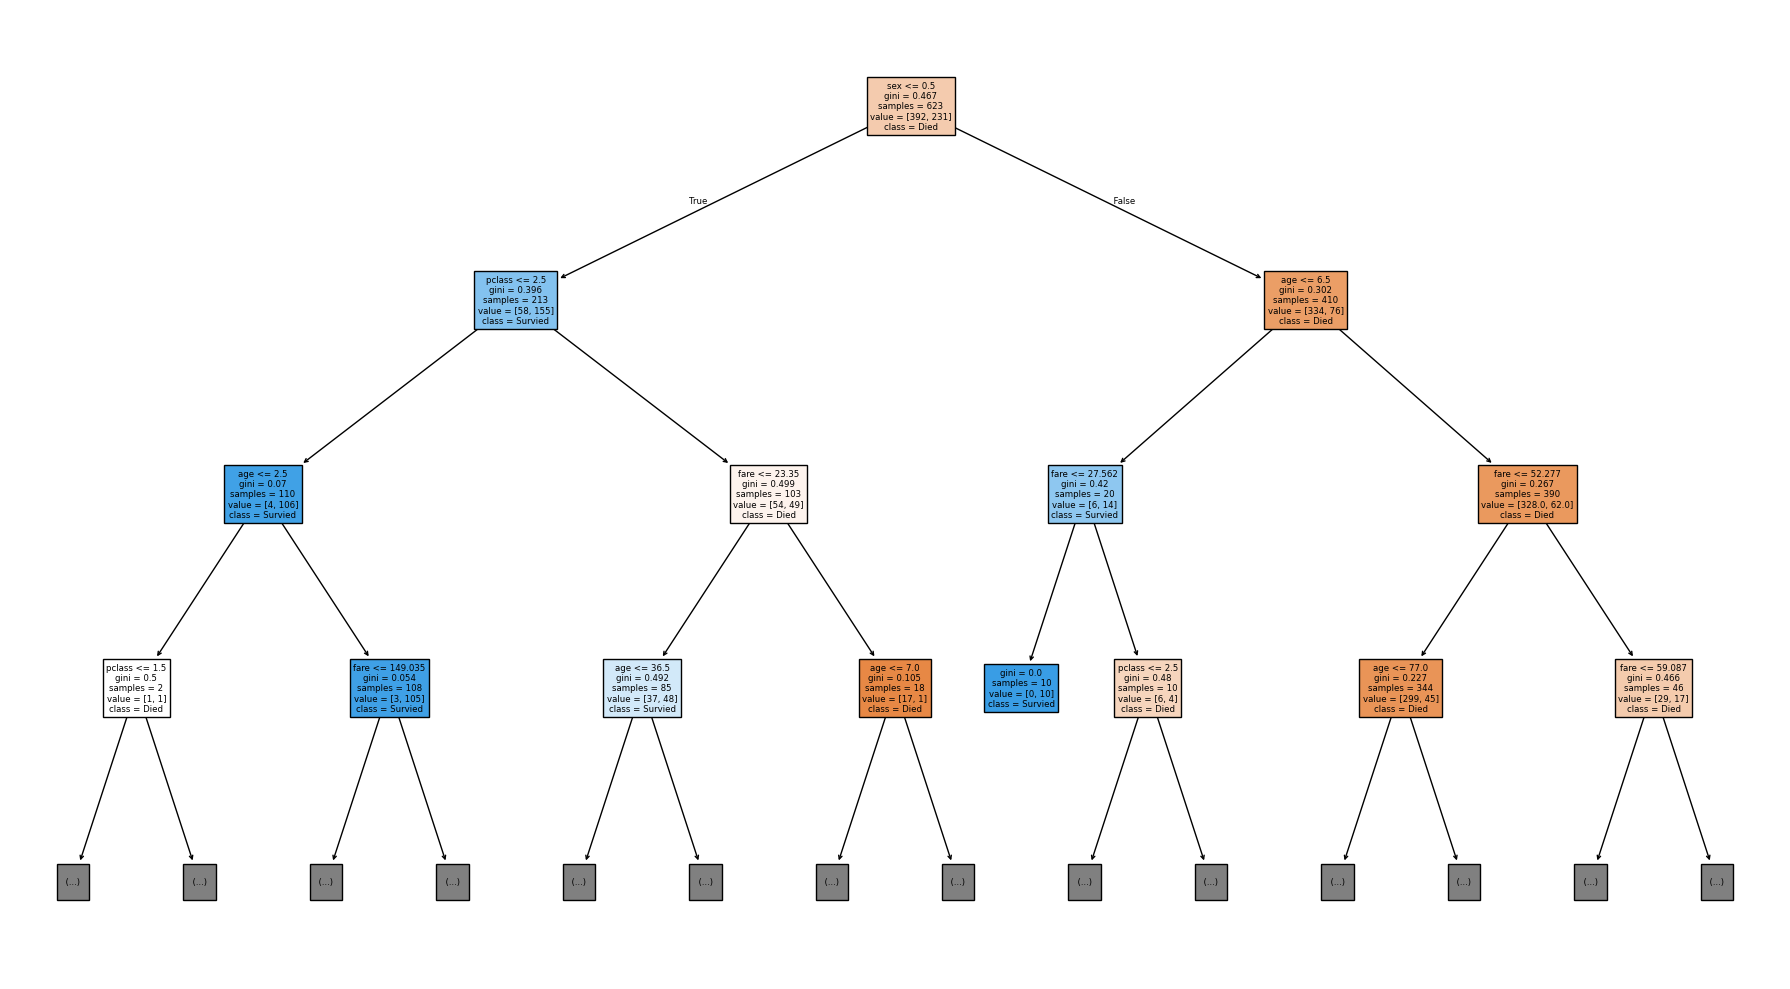

In [16]:
#ploting the deccisiomn trees 

from sklearn.tree import plot_tree

plt.figure(figsize=(18,10))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Died","Survied"],
    filled = True,
    max_depth=3
)
plt.tight_layout()
plt.show()

In [17]:
X_train.head()

,pclass,sex,fare,embarked,age
445,1,1,81.8583,2,4.0
650,3,1,7.8958,2,28.0
172,3,0,11.1333,2,1.0
450,2,1,27.7500,2,36.0
314,2,1,26.2500,2,43.0


Tree with the pre-pruning


depth = 2, acc = 0.77
depth = 3, acc = 0.81
depth = 4, acc = 0.82


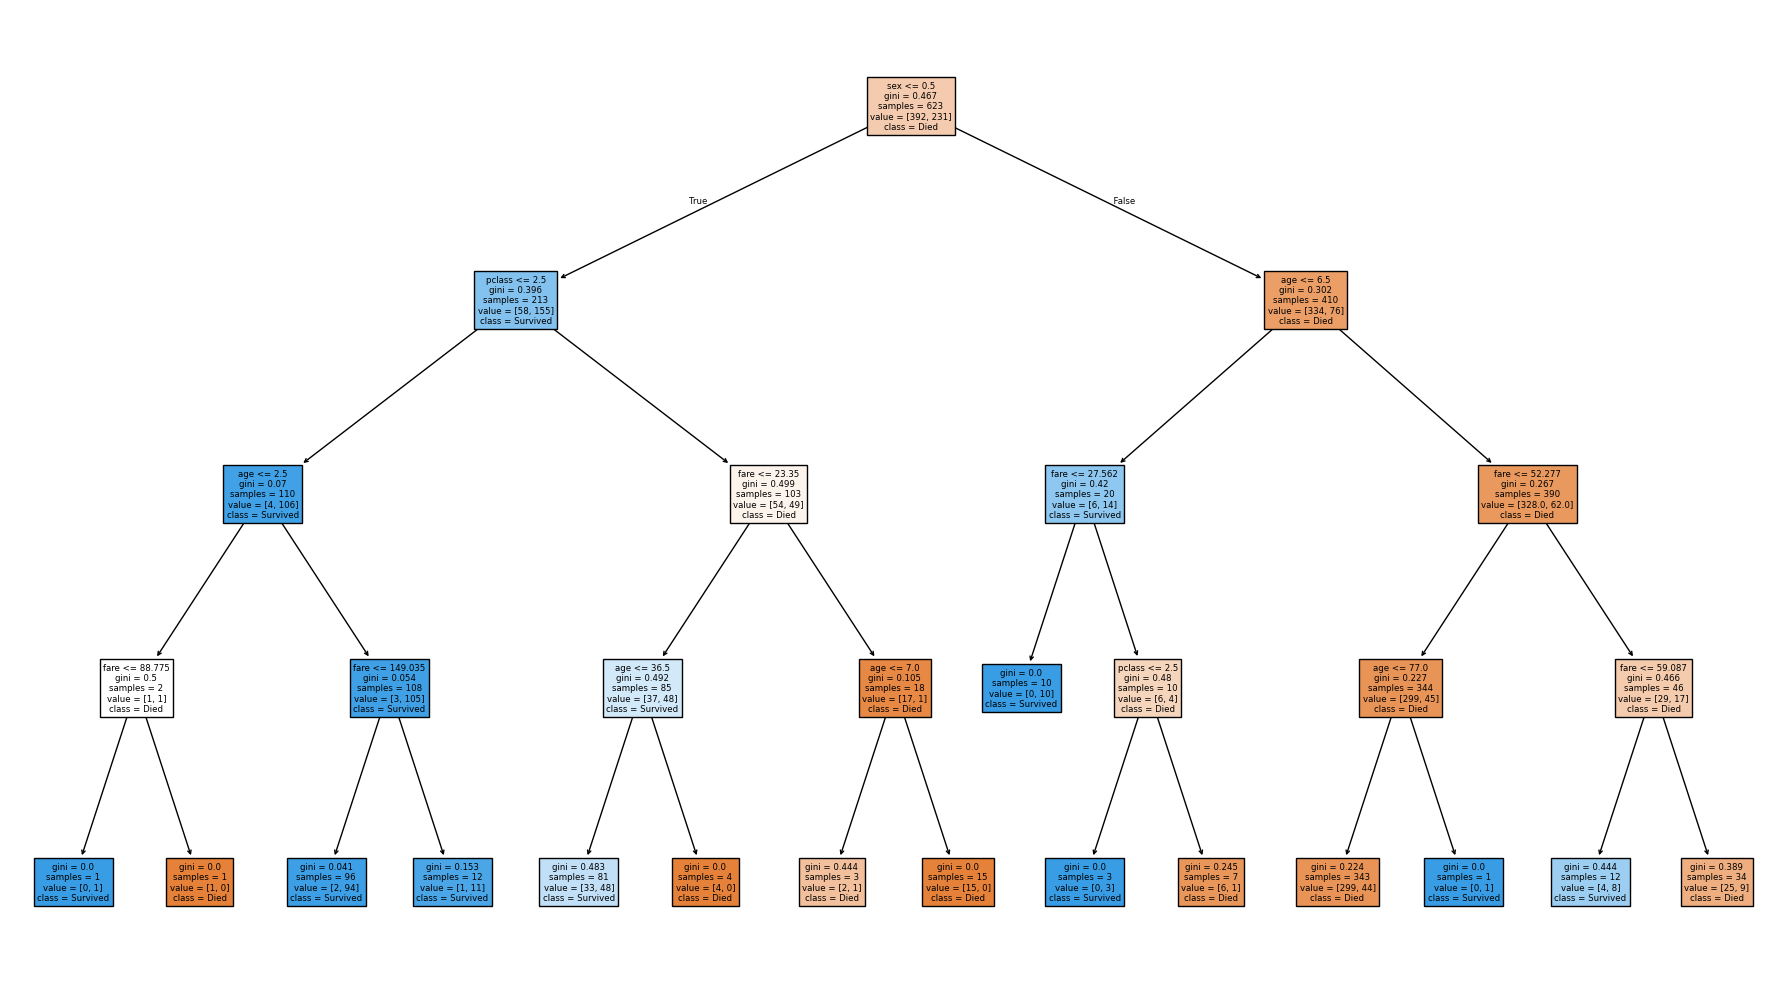

depth = 5, acc = 0.79
depth = 6, acc = 0.78
depth = 7, acc = 0.78
depth = 8, acc = 0.80
depth = 9, acc = 0.77


In [18]:
#max-ddepth nahi pata hai to ham usme pahe max depth shoow we are test with most of the max depth values
#for that we runn the loop
max_depth = [2, 3, 4, 5, 6, 7, 8, 9]

for dep in max_depth:

    model = DecisionTreeClassifier(max_depth=dep)
    model.fit(X_train, y_train)

    accuracy = model.score(X_test, y_test)

    print(f"depth = {dep}, acc = {accuracy:.2f}")

    if dep == 4:

        plt.figure(figsize=(18, 10))

        plot_tree(
            model,
            feature_names=X.columns,
            class_names=["Died", "Survived"],
            filled=True
        )

        plt.tight_layout()
        plt.show()
 

# from sklearn.tree import plot_tree

#         plt.figure(figsize=(18,10))
# plot_tree(
#     model,
#     feature_names=X.columns,
#     class_names=["Died","Survied"],
#     filled = True,
    
# )
# plt.tight_layout()
# plt.show()

Sample split = 5, acc = 0.8246268656716418
Sample split = 10, acc = 0.8246268656716418


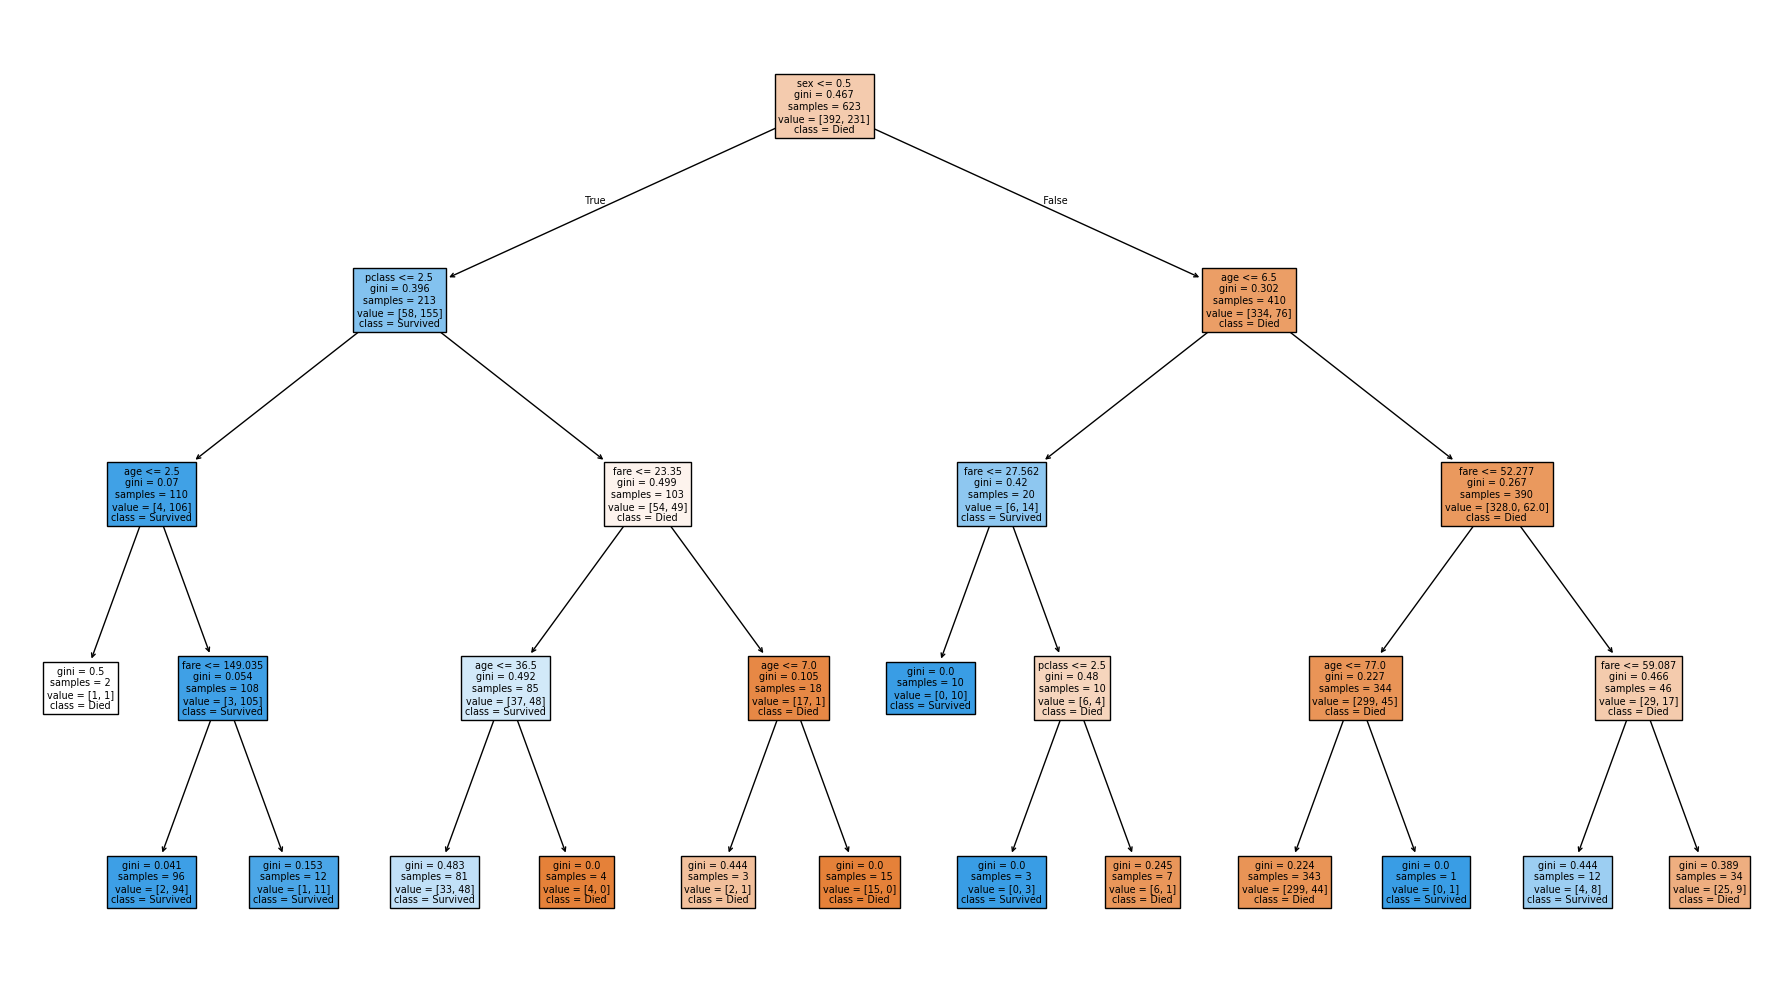

Sample split = 15, acc = 0.8171641791044776
Sample split = 20, acc = 0.8171641791044776
Sample split = 25, acc = 0.8208955223880597
Sample split = 30, acc = 0.8208955223880597
Sample split = 35, acc = 0.8208955223880597
Sample split = 40, acc = 0.8208955223880597


In [19]:
max_Sample_splits = [5,10,15,20,25,30,35,40]

for split in max_Sample_splits:
    model = DecisionTreeClassifier(
        max_depth=4,
        min_samples_split=split
    )

    model.fit(X_train, y_train)

    accuracy = model.score(X_test, y_test)

    print(f"Sample split = {split}, acc = {accuracy}")
    if split == 10:

        plt.figure(figsize=(18, 10))

        plot_tree(
            model,
            feature_names=X.columns,
            class_names=["Died", "Survived"],
            filled=True
        )

        plt.tight_layout()
        plt.show()

Decision Tree with  the pre_pruning

In [20]:
full_Tree=  DecisionTreeClassifier(random_state=42)
full_Tree.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [21]:
path= full_Tree.cost_complexity_pruning_path(X_train, y_train)

ccp_alphas = path.ccp_alphas

print(ccp_alphas)


[0.         0.         0.00013376 0.00013376 0.00022931 0.00032103
 0.00048409 0.00053505 0.00053505 0.00053505 0.00062746 0.00064205
 0.00077709 0.00085607 0.00093633 0.00096308 0.00096308 0.00096308
 0.00099875 0.00101659 0.00104193 0.0010478  0.00107009 0.00109238
 0.00115927 0.0012352  0.00123729 0.00129646 0.00132211 0.00133563
 0.00137583 0.00137583 0.00139708 0.00143228 0.00144145 0.00150482
 0.00151596 0.00152184 0.00171215 0.00183444 0.0019012  0.00195674
 0.00200642 0.00214018 0.00233474 0.0024077  0.00260835 0.00263292
 0.00278606 0.00280169 0.00284379 0.00288925 0.00299625 0.00302412
 0.00431144 0.00495299 0.00577849 0.00589431 0.0074248  0.01236198
 0.01787674 0.04065074 0.1323581 ]


In [22]:
#train the model for alphas

trees=[]

for alpha in ccp_alphas:
    model=DecisionTreeClassifier(random_state=42,ccp_alpha=alpha)
    model.fit(X_train, y_train)

    trees.append((model, alpha))

In [23]:
best_acc = 0
best_alpha = 0

for model, alpha in trees:
    curr_acc = model.score(X_test, y_test)

    if curr_acc > best_acc:
        best_acc = curr_acc
        best_alpha = alpha

print("Best accuracy:", best_acc)
print("Best alpha:", best_alpha)

Best accuracy: 0.8208955223880597
Best alpha: 0.0017121455323702516


In [24]:
bes_model=DecisionTreeClassifier(ccp_alpha=best_alpha)
bes_model.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


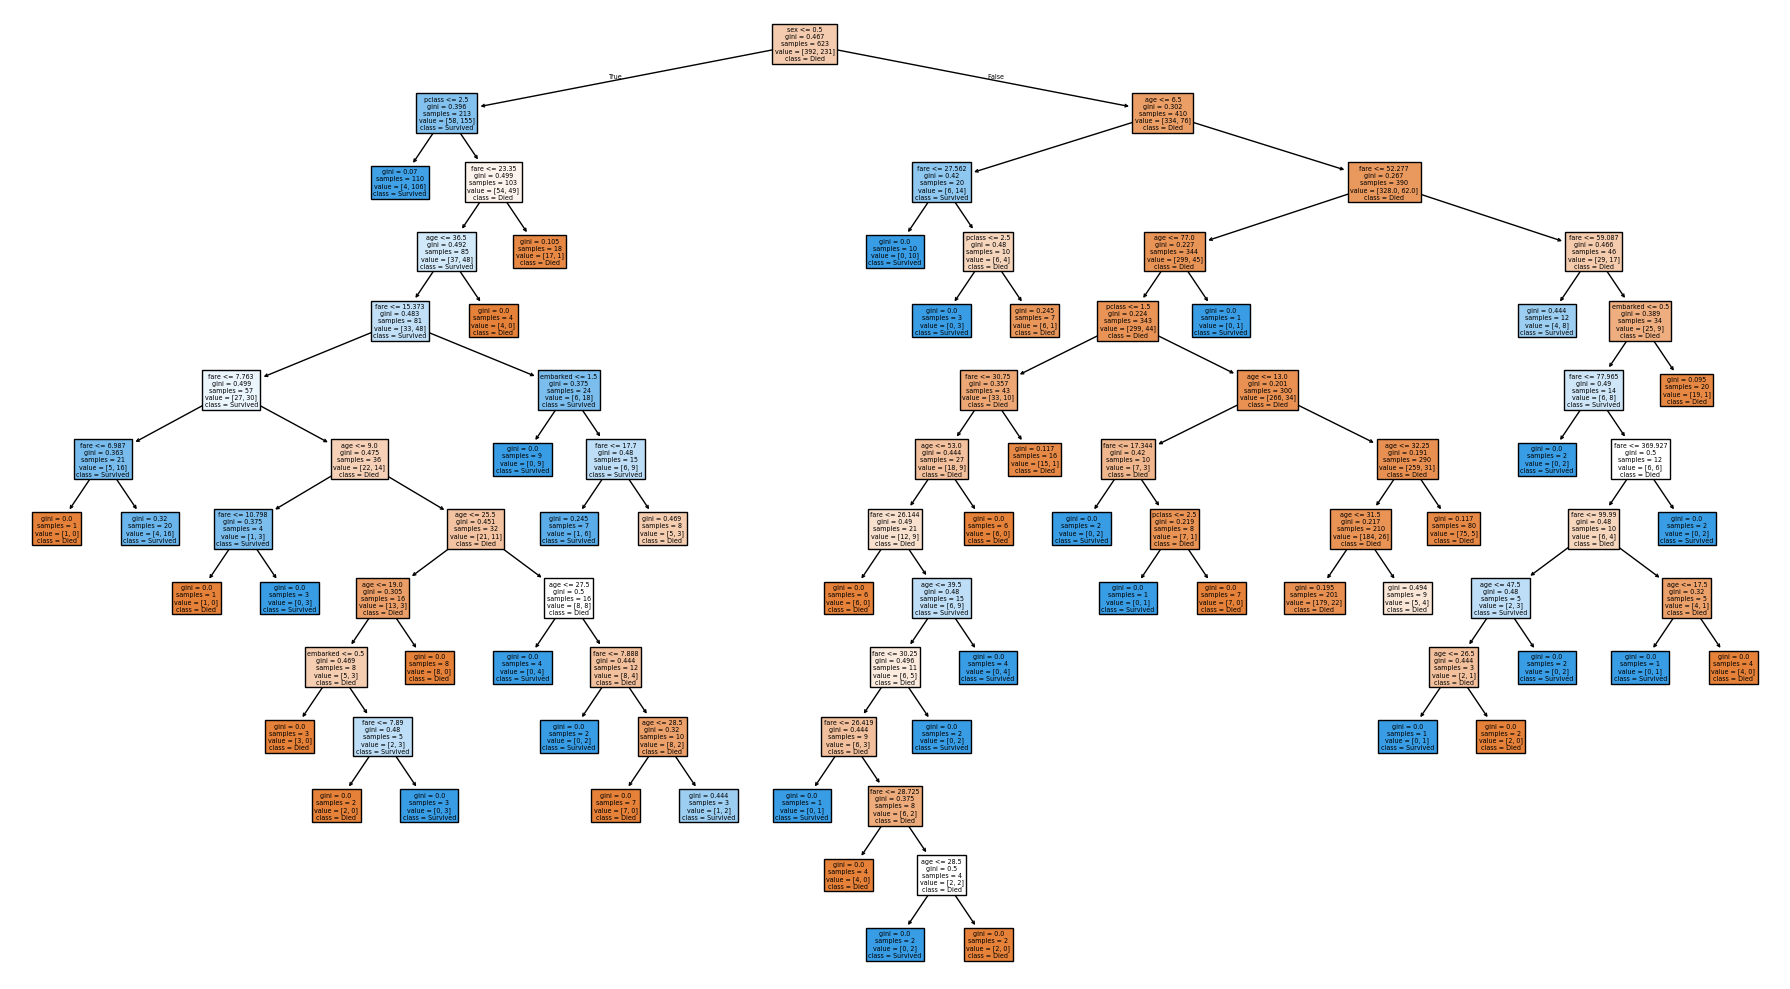

In [25]:
plt.figure(figsize=(18, 10))

plot_tree(
    bes_model,
    feature_names=X.columns,
    class_names=["Died", "Survived"],
    filled=True
)       
plt.tight_layout()
plt.show()